# Grid Search vs GridSearchCV — ML Notes

## 1. Grid Search là gì?

**Grid Search** là phương pháp tìm **hyperparameters** bằng cách thử **tất cả tổ hợp** giá trị do ta định nghĩa trước.

Ví dụ với Random Forest:

```python
param_grid = {
    "n_estimators": [50, 100],
    "max_depth": [3, 5, 10],
    "min_samples_split": [2, 5]
}
```

Số tổ hợp cần thử: `2 × 3 × 2 = 12`.

> Grid Search là **chiến lược tìm kiếm**, không quy định bắt buộc phải đánh giá bằng cách nào. Nếu chỉ thử trên một tập validation cố định thì kết quả có thể phụ thuộc vào cách chia dữ liệu.

## 2. Cross Validation (CV) là gì?

**K-Fold Cross Validation** chia **training set** thành `K` phần (folds):

1. Train trên `K-1` folds.
2. Validation trên fold còn lại.
3. Lặp `K` lần, mỗi fold làm validation một lần.
4. Tính điểm trung bình (và độ lệch chuẩn) của các lần đánh giá.

Ví dụ `cv=5`: mỗi cấu hình được đánh giá 5 lần trên các phần dữ liệu khác nhau.

```python
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(random_state=42)
scores = cross_val_score(model, X_train, y_train, cv=5, scoring="accuracy")
print("CV mean:", scores.mean())
print("CV std:", scores.std())
```

Với classification, khi truyền `cv=5`, sklearn thường dùng **StratifiedKFold** (không shuffle theo mặc định) để duy trì tỷ lệ lớp giữa các folds.

## 3. GridSearchCV là gì?

**GridSearchCV = Grid Search + Cross Validation**: thử từng tổ hợp hyperparameters và dùng CV để chấm điểm; chọn tổ hợp có **điểm CV trung bình** tốt nhất.

Quy trình:

1. Khai báo danh sách hyperparameters.
2. Sinh mọi tổ hợp.
3. Chạy K-Fold CV cho từng tổ hợp.
4. Chọn tổ hợp có điểm trung bình tốt nhất.
5. Mặc định (`refit=True`), **train lại** cấu hình tốt nhất trên **toàn bộ training set**.
6. Đánh giá một lần trên **test set** độc lập.

### Code mẫu (scikit-learn)

```python
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

model = RandomForestClassifier(random_state=42)

param_grid = {
    "n_estimators": [50, 100],
    "max_depth": [3, 5, 10],
    "min_samples_split": [2, 5]
}

grid = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
    refit=True
)

grid.fit(X_train, y_train)

print("Best params:", grid.best_params_)
print("Best CV score:", grid.best_score_)

best_model = grid.best_estimator_
print("Test accuracy:", best_model.score(X_test, y_test))
```

**Số lần fit:** `12 tổ hợp × 5 folds = 60` lần CV, cộng **1 lần refit** cấu hình tốt nhất ⇒ **61 lần fit** (theo thiết lập trên).

### Các thuộc tính cần nhớ

| Thuộc tính | Ý nghĩa |
|---|---|
| `best_params_` | Bộ hyperparameters có điểm CV tốt nhất |
| `best_score_` | Điểm CV trung bình tốt nhất |
| `best_estimator_` | Model được refit với bộ tham số tốt nhất (khi `refit=True`) |
| `cv_results_` | Kết quả chi tiết của mọi tổ hợp |

## 4. So sánh nhanh

| Tiêu chí | Grid Search | GridSearchCV |
|---|---|---|
| Bản chất | Chiến lược duyệt các tổ hợp tham số | Lớp có sẵn trong sklearn |
| Có thử mọi tổ hợp trong lưới? | Có | Có |
| Có bắt buộc dùng CV? | Không | Có |
| Chọn cấu hình theo | Cách đánh giá do người thực hiện thiết kế | Điểm CV trung bình theo `scoring` |
| Có tự refit cấu hình tốt nhất? | Tùy cách triển khai | Có, mặc định `refit=True` |

## 5. Khi nào dùng và lưu ý

- **Cross Validation**: khi muốn đánh giá độ ổn định của mô hình trên các cách chia train/validation.
- **GridSearchCV**: khi đã chọn thuật toán nhưng cần **tuning hyperparameters**.
- **RandomizedSearchCV**: cân nhắc khi lưới tham số quá lớn; chỉ lấy mẫu một số cấu hình thay vì duyệt hết.
- **Không dùng test set để chọn tham số**. Chỉ sử dụng test set sau khi đã hoàn tất lựa chọn mô hình.
- Nếu có chuẩn hóa hoặc PCA, nên đặt trong **Pipeline** và chạy GridSearchCV trên pipeline để tránh **data leakage** giữa các folds.
- Điểm CV cao nhất không đảm bảo điểm test cũng cao tương ứng; nên kiểm tra thêm F1, precision, recall nếu dữ liệu mất cân bằng.

## 6. Ghi nhớ một câu

> **Grid Search** = thử những bộ hyperparameters nào?  
> **Cross Validation** = đánh giá mỗi bộ đáng tin cậy ra sao?  
> **GridSearchCV** = kết hợp cả hai để chọn bộ hyperparameters tốt nhất theo CV.


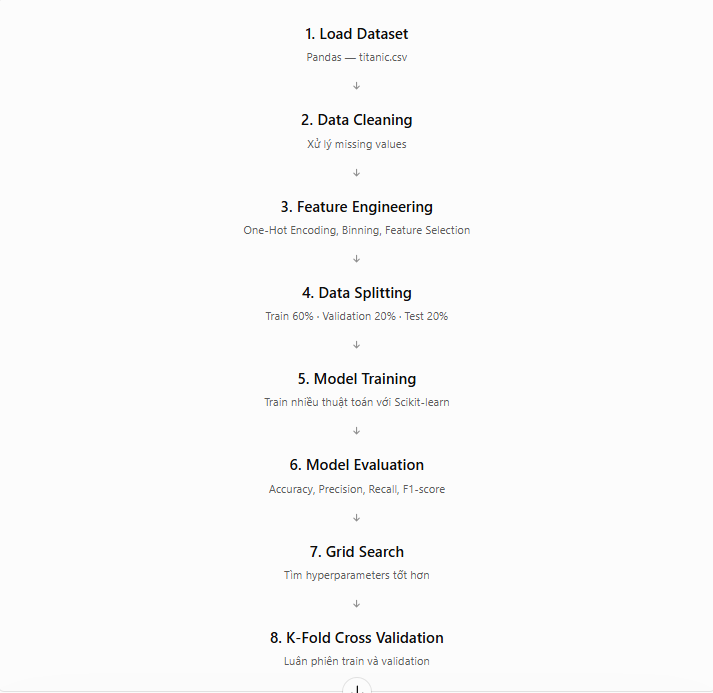
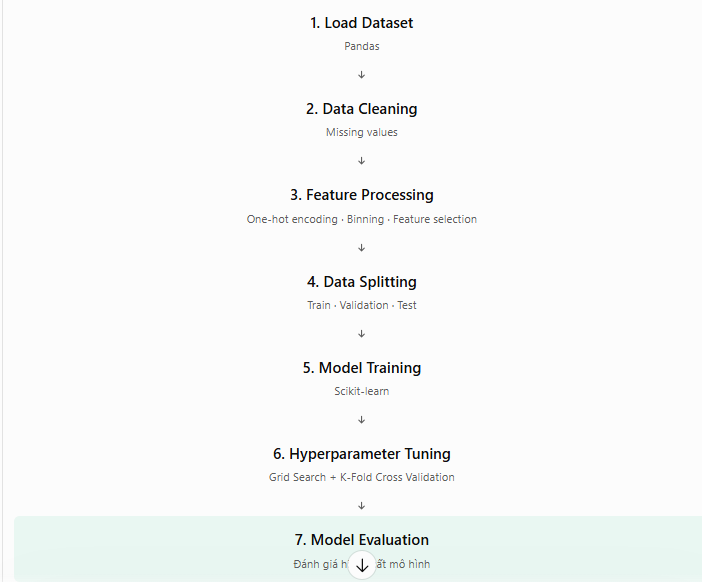